# 03 Modelling: Which Traits Still Matter Once the Others Are Held Constant?

**Goal:** build a simple, explainable model of prediabetes or diabetes from the 18 health and demographic traits in the cleaned BRFSS 2023 data, and use it to see which traits stay linked to the target when the others are accounted for (including age).

**Model:** logistic regression, compared with a baseline that predicts "no diabetes" for everyone.

**Data:** `brfss2023_diabetes_clean.csv`, produced by `01_data_preparation.ipynb` (300,760 respondents).

**Sections:** 1. Setup and split, 2. Baseline, 3. Logistic regression, 4. Evaluation, 5. Which traits matter, 6. Summary of modelling findings.

**Important:** this is a survey, so the model describes associations. It is not a diagnostic tool and does not show what causes diabetes.

In [3]:
import warnings
warnings.filterwarnings("ignore")   

import pandas as pd          
import numpy as np             
import matplotlib.pyplot as plt     
import seaborn as sns                

sns.set_theme(style="whitegrid")

df = pd.read_csv("brfss2023_diabetes_clean.csv")   
print(df.shape)

(300760, 20)


In [4]:
y = df["diabetes_binary"]                              # the target: 0 = no diabetes, 1 = prediabetes or diabetes
X = df.drop(columns=["diabetes_binary", "weight"])     # the 18 traits we use to predict it

print("Predictors:", X.shape[1])
print(list(X.columns))

Predictors: 18
['high_bp', 'high_chol', 'chol_check', 'bmi', 'smoker', 'stroke', 'heart_disease', 'phys_activity', 'heavy_drinker', 'any_healthcare', 'no_doc_cost', 'gen_health', 'ment_health_days', 'phys_health_days', 'diff_walk', 'sex', 'age_group', 'education']


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% of people are held back for testing
    stratify=y,           # keep the same 82.7% / 17.3% balance in both parts
    random_state=42,      # fixed seed so the split is the same every time
)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)
print()
print("Share with prediabetes or diabetes:")
print("  all people:", round(y.mean(), 3))
print("  training:  ", round(y_train.mean(), 3))
print("  test:      ", round(y_test.mean(), 3))

Training set: (240608, 18)
Test set:     (60152, 18)

Share with prediabetes or diabetes:
  all people: 0.173
  training:   0.173
  test:       0.173


## 2. Baseline: predict "no diabetes" for everyone

A model is only useful if it does better than a trivial guess. The baseline below ignores every trait and gives everyone the most common answer (no diabetes). Because about 82.7% of people fall in that group, the baseline gets a high accuracy without finding a single person with prediabetes or diabetes. That is why accuracy alone is a poor measure here, and why the results use recall, precision and ROC-AUC as well.

**What the measures mean (for the group with prediabetes or diabetes):**
- **Accuracy:** the share of all predictions that are right.
- **Recall:** of the people who have it, the share the model catches.
- **Precision:** of the people the model flags, the share who really have it.
- **ROC-AUC:** how well the model ranks people from lower to higher risk. 0.5 is no better than a coin flip, and 1.0 is perfect.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score, confusion_matrix

# The baseline: always predict the most common answer in the training set (0 = no diabetes)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

# Predictions for the test set
base_pred = baseline.predict(X_test)                 # a 0 or 1 for each person
base_score = baseline.predict_proba(X_test)[:, 1]    # a risk score for each person (all the same here)

print("Accuracy: ", round(accuracy_score(y_test, base_pred), 3))
print("Recall:   ", round(recall_score(y_test, base_pred), 3))
print("Precision:", round(precision_score(y_test, base_pred, zero_division=0), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, base_score), 3))
print()
print("Confusion matrix (rows = truth, columns = prediction):")
print(pd.DataFrame(confusion_matrix(y_test, base_pred),
                   index=["truly no diabetes", "truly prediabetes/diabetes"],
                   columns=["predicted no", "predicted yes"]))

Accuracy:  0.827
Recall:    0.0
Precision: 0.0
ROC-AUC:   0.5

Confusion matrix (rows = truth, columns = prediction):
                            predicted no  predicted yes
truly no diabetes                  49741              0
truly prediabetes/diabetes         10411              0


**Finding:** predicting "no diabetes" for everyone gets an accuracy of 82.7% on the test set but finds none of the 10,411 people with prediabetes or diabetes (recall 0.0), and its ROC-AUC is 0.5, no better than a coin flip. Any real model has to beat these numbers on recall and ROC-AUC, not only on accuracy.

## 3. Logistic regression

Logistic regression gives each person a risk score between 0 and 1 from all 18 traits together. It is fitted on the **training set only**.

Two choices matter here:
- **Standardizing the traits.** Each trait is rescaled so a typical value is 0 and one "standard deviation" is 1. This puts yes/no flags, BMI and age on the same scale, so their effects can be compared in section 5. The rescaling is learned from the training set and then applied to the test set, so nothing from the test set leaks into the model.
- **Balancing the classes.** Only 17.3% of people have prediabetes or diabetes, and a model can score well by ignoring them (as the baseline did). `class_weight="balanced"` makes mistakes on that smaller group count more, so the model tries to find them. The cost is more false alarms, and the risk scores no longer match the real 17% rate, so they are good for **ranking** people, not for quoting a probability.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# A pipeline runs the steps in order: first standardize the traits, then fit the model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
)

model.fit(X_train, y_train)    # learn from the training set only

# Did the model finish learning? (the number of rounds it used should be well below 1000)
n_rounds = model.named_steps["logisticregression"].n_iter_[0]
print("Model fitted on", len(X_train), "people")
print("Rounds used:", n_rounds, "(limit 1000)")

Model fitted on 240608 people
Rounds used: 13 (limit 1000)


**Finding:** the model was fitted on the 240,608 training people and settled in 13 rounds, well within the limit of 1000, so the result is reliable.

## 4. Evaluation on the test set

The model is now scored on the 60,152 people it has never seen, and compared with the baseline.

**Reading the results:**
- With `class_weight="balanced"`, the model deliberately flags more people so it can find more of those who have prediabetes or diabetes. **Accuracy will therefore fall below the baseline's 82.7%, and that is expected**: the baseline looked good only because it flagged nobody.
- **Recall** shows how many people with prediabetes or diabetes the model catches. **Precision** shows how many of the people it flags really have it. Raising one usually lowers the other.
- **F1** combines recall and precision into one number, and **ROC-AUC** measures how well the model ranks people from lower to higher risk (0.5 = coin flip, 1.0 = perfect).

In [9]:
from sklearn.metrics import f1_score

pred = model.predict(X_test)                    # a 0 or 1 for each test person (cutoff 0.5)
score = model.predict_proba(X_test)[:, 1]       # a risk score between 0 and 1 for each person

results = pd.DataFrame({
    "baseline": [accuracy_score(y_test, base_pred),
                 recall_score(y_test, base_pred),
                 precision_score(y_test, base_pred, zero_division=0),
                 f1_score(y_test, base_pred, zero_division=0),
                 roc_auc_score(y_test, base_score)],
    "logistic regression": [accuracy_score(y_test, pred),
                            recall_score(y_test, pred),
                            precision_score(y_test, pred),
                            f1_score(y_test, pred),
                            roc_auc_score(y_test, score)],
}, index=["accuracy", "recall", "precision", "F1", "ROC-AUC"])

results.round(3)

,baseline,logistic regression
accuracy,0.827,0.714
recall,0.000,0.741
precision,0.000,0.347
F1,0.000,0.473
ROC-AUC,0.500,0.799


In [10]:
cm = pd.DataFrame(confusion_matrix(y_test, pred),
                  index=["truly no diabetes", "truly prediabetes/diabetes"],
                  columns=["predicted no", "predicted yes"])
print(cm)

                            predicted no  predicted yes
truly no diabetes                  35255          14486
truly prediabetes/diabetes          2699           7712


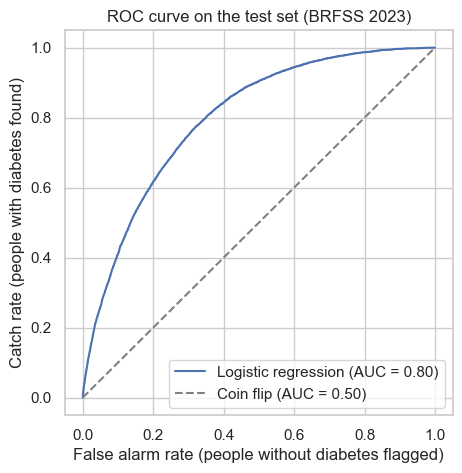

In [11]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, score)    # false alarm rate and catch rate at every cutoff

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y_test, score):.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Coin flip (AUC = 0.50)")
plt.xlabel("False alarm rate (people without diabetes flagged)")
plt.ylabel("Catch rate (people with diabetes found)")
plt.title("ROC curve on the test set (BRFSS 2023)")
plt.legend()
plt.show()

**Finding:** on the 60,152 test people, logistic regression reaches a ROC-AUC of **0.80** (baseline 0.50), so it ranks people by risk reasonably well, though not strongly. At the default cutoff it finds **74.1%** of the people with prediabetes or diabetes (7,712 of 10,411) and misses 2,699. The cost is false alarms: it flags 22,198 people, and only **34.7%** of them really have it (14,486 false alarms). It correctly clears 70.9% of the people without it.

Accuracy (71.4%) is lower than the baseline's 82.7%. This is expected, because the baseline flagged nobody and so found no one. Precision of 34.7% is about twice the 17.3% base rate, so a flagged person is about twice as likely as a random person to have prediabetes or diabetes, but most flags are still wrong.

The moderate result matches the EDA: the groups overlap on every trait, so no combination of these 18 traits separates them cleanly. This is a descriptive model of survey data, not a screening tool.

## 5. Which traits matter once the others are held constant?

Each trait gets a **coefficient**: positive means higher odds of prediabetes or diabetes, negative means lower. It shows the effect of that trait with all the others held constant, including age, which the EDA could only check visually.

Because the traits were standardized, each coefficient is the effect of a **one standard deviation** increase, so traits can be compared. The table also shows the **odds ratio** (the coefficient converted): 1.0 means no link, 1.5 means 50% higher odds, and 0.8 means 20% lower odds.

**Reading the results:** the odds ratios above are per standard deviation, which is good for ranking traits against each other but not the real "yes vs no" effect. For a yes/no trait, one standard deviation is only part of the jump from "no" to "yes" (about half for common traits, much less for rare ones), so these odds ratios understate it. The next table converts them to real units. Traits that overlap in meaning (general health, physical health days, difficulty walking) share credit, so each one's coefficient looks smaller than it would alone.

,coefficient,odds_ratio
gen_health,0.50,1.65
age_group,0.45,1.57
bmi,0.43,1.54
high_bp,0.32,1.38
high_chol,0.28,1.33
chol_check,0.22,1.25
heart_disease,0.08,1.08
diff_walk,0.05,1.06
stroke,0.04,1.04
no_doc_cost,0.03,1.03


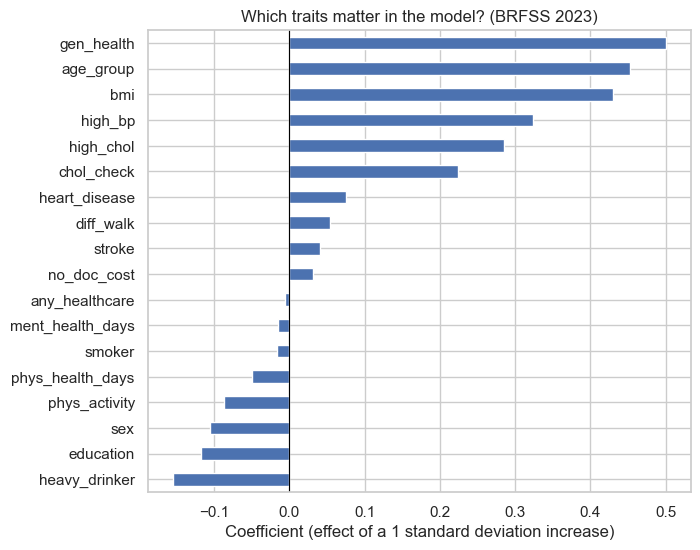

In [12]:
# The model's learned weight for each trait (in standardized units)
coefs = pd.Series(model.named_steps["logisticregression"].coef_[0], index=X_train.columns)

# Table: coefficient and odds ratio, largest first
effects = pd.DataFrame({"coefficient": coefs, "odds_ratio": np.exp(coefs)})
effects = effects.sort_values("coefficient", ascending=False)
display(effects.round(2))

# Chart: bars to the right raise the odds, bars to the left lower them
coefs.sort_values().plot(kind="barh", figsize=(7, 6))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (effect of a 1 standard deviation increase)")
plt.title("Which traits matter in the model? (BRFSS 2023)")
plt.show()

**Finding:** with all 18 traits in the model together, the strongest links are self-rated general health (odds ratio 1.65 per standard deviation), age group (1.57), BMI (1.54), high blood pressure (1.38) and high cholesterol (1.33). A recent cholesterol check also has a positive coefficient (1.25), which most likely reflects people with a diagnosis seeing doctors more often, not a risk factor.

Compared with the EDA, **age and BMI move up** (age was 6th on the common scale and is now 2nd, BMI 4th and now 3rd), so older age and higher BMI go with higher odds even with blood pressure, cholesterol and general health held constant. **Difficulty walking, heart disease and stroke shrink to near zero** (coefficients 0.05, 0.08 and 0.04) although they had large gaps in the EDA, so most of their link with diabetes is shared with general health, age, BMI and blood pressure, and some may be consequences of diabetes.

Physical activity (-0.09), sex (-0.11, women have lower odds), education (-0.12) and heavy drinking (-0.15) have small negative coefficients. Small negative values on overlapping traits (physical health days, mental health days, smoking) should not be read as protective effects. These are estimates from one sample without confidence intervals, so they show direction and rough size, not exact effects.

In [13]:
sd = X_train.std()              # how much each trait varies in the training set
real_coef = coefs / sd          # effect of ONE real unit instead of one standard deviation

# What one unit means for each trait
units = {c: "yes vs no" for c in X_train.columns}     # most traits are yes/no
units.update({
    "sex": "female vs male",
    "bmi": "per 1 BMI point",
    "age_group": "per 5-year age band",
    "gen_health": "per step towards poor health",
    "education": "per education level",
    "ment_health_days": "per extra day",
    "phys_health_days": "per extra day",
})

real = pd.DataFrame({"odds_ratio": np.exp(real_coef), "unit": pd.Series(units)})
real.sort_values("odds_ratio", ascending=False).round(2)

,odds_ratio,unit
chol_check,3.46,yes vs no
high_bp,1.92,yes vs no
high_chol,1.78,yes vs no
gen_health,1.62,per step towards poor health
heart_disease,1.30,yes vs no
stroke,1.22,yes vs no
diff_walk,1.16,yes vs no
age_group,1.14,per 5-year age band
no_doc_cost,1.13,yes vs no
bmi,1.07,per 1 BMI point


**Finding:** converted to real units, and holding the other traits constant, the main effects are:

- **High blood pressure:** about 1.9 times the odds of prediabetes or diabetes. **High cholesterol:** about 1.8 times.
- **General health:** 1.62 times per step towards poor health (about 7 times across the four steps from excellent to poor, if the effect is steady).
- **Age:** 1.14 per 5-year band (about 1.3 per ten years). **BMI:** 1.07 per point (about 1.4 per 5 points). **Education:** 0.88 per level.
- **Physical activity** (0.81) and **female sex** (0.81) go with about 19% lower odds.
- **Heart disease** (1.30), **stroke** (1.22), **difficulty walking** (1.16) and **cost barriers to seeing a doctor** (1.13) are modest once the other traits are accounted for.
- **Mental health days, physical health days, smoking and health coverage** have essentially no independent link (0.97-1.00).

Two results should not be read as risk or protection: a **recent cholesterol check (3.46)** most likely reflects people with a diagnosis being tested more often, and **heavy drinking (0.52)** may reflect people cutting back after a diagnosis; this data cannot confirm either.

The units differ between rows ("yes vs no", "per BMI point", "per age band"), so this table explains the size of each effect but is not a ranking. The standardized chart above is the better ranking. These are estimates from one sample without confidence intervals.

## 6. Summary of modelling findings

| Question | Answer |
|---|---|
| Setup | 300,760 respondents split 80/20 into a training set (240,608) and a test set (60,152), keeping the 17.3% share with prediabetes or diabetes in both. Model: logistic regression on 18 standardized traits with balanced class weights. The survey weight was not used. |
| Baseline | Predicting "no diabetes" for everyone gives 82.7% accuracy but finds none of the 10,411 people with prediabetes or diabetes (recall 0, ROC-AUC 0.50). |
| How well does the model do? | **ROC-AUC 0.80** on the unseen test set, so it ranks people by risk reasonably well, though not strongly. It finds **74.1%** of people with prediabetes or diabetes (7,712 of 10,411) but flags 22,198 people, and only **34.7%** of the flagged are right (14,486 false alarms). Accuracy falls to 71.4%, which is expected because the baseline flagged nobody. |
| Which traits matter most (ranked)? | General health (odds ratio 1.65 per standard deviation), age (1.57), BMI (1.54), high blood pressure (1.38) and high cholesterol (1.33). Compared with the EDA, age and BMI move up. Difficulty walking, heart disease and stroke shrink to near zero, so most of their link is shared with the traits above. |
| How big are the effects? | With the other traits held constant: high blood pressure about 1.9 times the odds, high cholesterol about 1.8 times, general health 1.62 per step towards poor health, age 1.14 per 5-year band, BMI 1.07 per point, education 0.88 per level, and physical activity and female sex about 0.81 (19% lower odds). Mental health days, physical health days, smoking and health coverage have essentially no independent link (0.97-1.00). |
| What should not be read as risk? | A recent cholesterol check (3.46) most likely reflects people with a diagnosis being tested more often. Heavy drinking (0.52) may reflect people cutting back after a diagnosis. This data cannot confirm either. |